# Comparing strategies on five seasons

Every strategy asks the solver each week for the best squad given the forecasts, with hits allowed and no chips. `hK` plans $K$ weeks ahead with equal weights, `hKd` weights week $k$ by $0.85^{k-1}$, `hKb` by the slopes estimated on the other four seasons. `freeze` builds a squad in week 1 and never transfers. `site*` use the archive column that contains the results and are not comparable.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, '.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import data, model, sim, bank, milp
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.6, 'font.size': 9})
os.makedirs('figs', exist_ok=True)
save = lambda fig, nm: [fig.savefig(f'figs/{nm}.{ext}', bbox_inches='tight') for ext in ['pdf', 'png']]

In [2]:
bt = pd.read_csv('data/cache/backtest.csv')
order = ['freeze', 'h1', 'h2', 'h3', 'h5', 'h8', 'h3d', 'h5d', 'h8d', 'h5b', 'h8b', 'site1', 'site3']
tot = bt.groupby(['season', 'policy']).pts.sum().unstack()[[c for c in order if c in set(bt.policy)]]
summ = pd.concat([tot, tot.mean().rename('mean').to_frame().T, (tot.std() / np.sqrt(len(tot))).rename('se').to_frame().T])
summ.round(0).astype(int)

policy,freeze,h1,h2,h3,h5,h8,h3d,h5d,h8d,h5b,h8b,site1,site3
2021-22,2135,2154,2147,2175,2242,2312,2159,2203,2127,2216,2211,3084,3039
2022-23,1595,2069,2181,2175,2118,2154,1997,2214,2050,2133,2070,2868,2801
2023-24,2023,2142,2159,2074,2115,2123,2078,2226,2186,2131,2083,2734,2817
2024-25,1801,1972,2033,2224,2221,2205,2244,2197,2233,2177,2239,2786,2739
2025-26,1276,1827,1943,1999,1997,1953,1908,1975,1927,2003,1983,2354,2153
mean,1766,2033,2093,2129,2139,2149,2077,2163,2105,2132,2117,2765,2710
se,154,61,45,41,44,59,59,47,54,36,47,119,148


In [3]:
# paired against the myopic policy, which removes most of the season to season variance
d = tot.sub(tot['h1'], axis=0).drop(columns=['h1'])
pd.DataFrame(dict(mean=d.mean(), se=d.std() / np.sqrt(len(d)))).round(1).T

policy,freeze,h2,h3,h5,h8,h3d,h5d,h8d,h5b,h8b,site1,site3
mean,-266.8,59.8,96.6,105.8,116.6,44.4,130.2,71.8,99.2,84.4,732.4,677.0
se,104.0,24.7,56.0,47.9,41.7,63.2,30.2,52.6,39.9,57.8,74.8,94.2


[None, None]

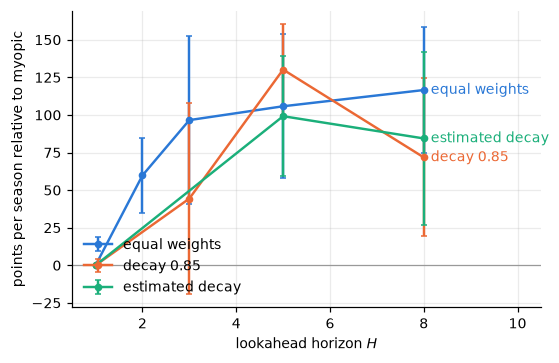

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
grp = [('equal weights', ['h1', 'h2', 'h3', 'h5', 'h8'], [1, 2, 3, 5, 8]),
       ('decay 0.85', ['h1', 'h3d', 'h5d', 'h8d'], [1, 3, 5, 8]),
       ('estimated decay', ['h1', 'h5b', 'h8b'], [1, 5, 8])]
for (nm, cols, H), col in zip(grp, C):
    y = d.reindex(columns=cols).fillna(0)
    ax.errorbar(H, y.mean(), yerr=y.std() / np.sqrt(len(y)), color=col, marker='o', ms=4, capsize=2, label=nm)
    ax.text(H[-1] + 0.15, y.mean().iloc[-1], nm, color=col, va='center')
ax.axhline(0, color='0.6', lw=0.8)
ax.set_xlabel('lookahead horizon $H$'); ax.set_ylabel('points per season relative to myopic'); ax.set_xlim(0.5, 10.5)
ax.legend(frameon=False, loc='lower left')
save(fig, 'horizon')

## Against real managers

The game's own average score per gameweek (`average_entry_score` from end of season copies of the FPL API, see `data.get_snap`), summed over the season. Real managers use chips and team news, and the average also includes abandoned teams.

In [5]:
avg = pd.Series({s: data.avg_score(s).sum() for s in data.SEASONS})
cmp = tot[['h1', 'h3', 'h5d', 'h5b', 'h8']].assign(avg=avg)
da = tot.drop(columns=[c for c in ['site1', 'site3'] if c in tot]).sub(avg, axis=0)
print(cmp)
pd.DataFrame(dict(mean=da.mean(), se=da.std() / np.sqrt(len(da)), worst=da.min())).round(0).T

policy       h1      h3     h5d     h5b      h8   avg
season                                               
2021-22  2154.0  2175.0  2203.0  2216.0  2312.0  1923
2022-23  2069.0  2175.0  2214.0  2133.0  2154.0  2026
2023-24  2142.0  2074.0  2226.0  2131.0  2123.0  2003
2024-25  1972.0  2224.0  2197.0  2177.0  2205.0  2008
2025-26  1827.0  1999.0  1975.0  2003.0  1953.0  1895


policy,freeze,h1,h2,h3,h5,h8,h3d,h5d,h8d,h5b,h8b
mean,-205.0,62.0,122.0,158.0,168.0,178.0,106.0,192.0,134.0,161.0,146.0
se,149.0,55.0,37.0,34.0,44.0,57.0,56.0,33.0,44.0,35.0,48.0
worst,-619.0,-68.0,25.0,71.0,92.0,58.0,-29.0,80.0,24.0,107.0,44.0


## The hindsight run

`U` is the best forecast total over a pruned candidate pool with every week's forecasts known in advance: the solver picks the whole season's squads at once from the season's forecasts (`sim.path_bound`). `WS` is the same computation with realized points in place of forecasts, the perfect-foresight score.

In [6]:
import pickle, os
rows = []
for s in data.SEASONS:
    r = dict(season=s)
    if os.path.exists(f'data/cache/bound_{s}.pkl'):
        b, cand = pickle.load(open(f'data/cache/bound_{s}.pkl', 'rb')); r['U'] = b['obj']; r['pool'] = len(cand)
    if os.path.exists(f'data/cache/ws_{s}.pkl'):
        w, _ = pickle.load(open(f'data/cache/ws_{s}.pkl', 'rb')); r['WS'] = w['obj']
    for pol in ['h1', 'h3', 'h5b', 'h8b']:
        g = bt[(bt.season == s) & (bt.policy == pol)]
        if len(g):
            r[f'rho_{pol}'] = g.rho.sum(); r[f'pts_{pol}'] = g.pts.sum()
    rows.append(r)
bnd = pd.DataFrame(rows).set_index('season')
dual = pd.read_csv('data/cache/bound_dual.csv').set_index('season')   # cbc best possible when it stopped on the time limit
bnd['U_dual'] = dual.U_dual
for pol in ['h1', 'h3', 'h5b', 'h8b']:
    if f'rho_{pol}' in bnd:
        bnd[f'gap_{pol}'] = bnd['U'] - bnd[f'rho_{pol}']
        bnd[f'gapdual_{pol}'] = bnd['U_dual'] - bnd[f'rho_{pol}']
bnd.round(0)

,U,pool,WS,rho_h1,pts_h1,rho_h3,pts_h3,rho_h5b,pts_h5b,rho_h8b,pts_h8b,U_dual,gap_h1,gapdual_h1,gap_h3,gapdual_h3,gap_h5b,gapdual_h5b,gap_h8b,gapdual_h8b
season,,,,,,,,,,,,,,,,,,,,
2021-22,2232.0,307,5147.0,2071.0,2154.0,2175.0,2175.0,2211.0,2216.0,2211.0,2211.0,2350.0,162.0,280.0,57.0,175.0,22.0,139.0,22.0,139.0
2022-23,2114.0,335,4783.0,1997.0,2069.0,2086.0,2175.0,2098.0,2133.0,2098.0,2070.0,2189.0,118.0,192.0,28.0,102.0,16.0,90.0,17.0,91.0
2023-24,2072.0,301,5030.0,2003.0,2142.0,2030.0,2074.0,2059.0,2131.0,2050.0,2083.0,2148.0,69.0,145.0,41.0,118.0,13.0,90.0,22.0,99.0
2024-25,2109.0,253,4834.0,1923.0,1972.0,2017.0,2224.0,2042.0,2177.0,2042.0,2239.0,2142.0,186.0,219.0,93.0,125.0,68.0,100.0,68.0,100.0
2025-26,1962.0,245,4893.0,1820.0,1827.0,1877.0,1999.0,1897.0,2003.0,1895.0,1983.0,1984.0,143.0,165.0,85.0,107.0,65.0,87.0,68.0,89.0


`U` is the best solution the solver found before its time limit and `U_dual` is the solver's dual value when it stopped. `gap` is `U` minus a strategy's forecast sum and `gapdual` is `U_dual` minus it, both over the pruned player pool. Realized points minus the forecast sum runs slightly above zero for every model-based strategy that transfers and slightly below for `freeze`; part of the positive side is automatic substitutions, which add to the realized score but not to the forecast of the named eleven. `U_dual` is read from `data/cache/bound_dual.csv`, which was recorded in an earlier run, apparently from CBC's log output; no script in the repository regenerates it.

## What if the forecasts were noisier

The strategy plans on a corrupted forecast (normal noise of the given standard deviation added to every player-week) while it is scored on real outcomes. The dashed series first pull the noisy forecast toward the average by the factor $\tau^2/(\tau^2 + \sigma^2)$.

policy,h1,h3,h8,h1_shrunk,h3_shrunk,h8_shrunk
noise,,,,,,
0.0,2033.0,2129.0,2149.0,NaN,NaN,NaN
0.5,2011.0,2052.0,2074.0,NaN,NaN,NaN
1.0,1950.0,1915.0,1885.0,1876.0,1994.0,2019.0
2.0,1388.0,1220.0,1288.0,1780.0,1875.0,NaN


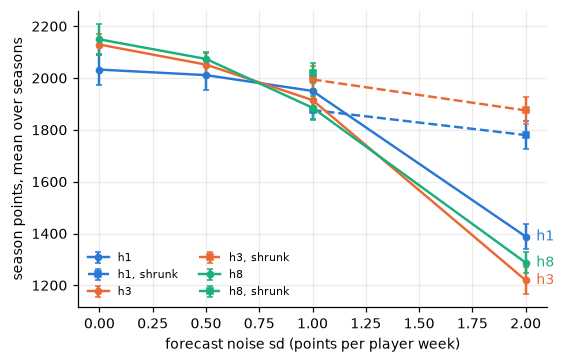

In [7]:
nz = pd.read_csv('data/cache/noise.csv')
n0 = bt[bt.policy.isin(['h1', 'h3', 'h8'])].groupby(['season', 'policy']).pts.sum().reset_index().assign(noise=0.0, seed=0)
nn = nz.groupby(['season', 'policy', 'noise', 'seed']).pts.sum().reset_index()
allp = pd.concat([n0, nn]).groupby(['policy', 'noise']).pts.agg(['mean', 'sem']).reset_index()
sh = pd.read_csv('data/cache/noise_shrink.csv') if os.path.exists('data/cache/noise_shrink.csv') else None
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for pol, col in zip(['h1', 'h3', 'h8'], C):
    g = allp[allp.policy == pol]
    ax.errorbar(g.noise, g['mean'], yerr=g['sem'], color=col, marker='o', ms=4, capsize=2, label=pol)
    ax.text(g.noise.iloc[-1] + 0.05, g['mean'].iloc[-1], pol, color=col, va='center')
    if sh is not None:
        gs = sh[sh.policy == pol].groupby(['season', 'noise', 'seed']).pts.sum().reset_index().groupby('noise').pts.agg(['mean', 'sem']).reset_index()
        ax.errorbar(gs.noise, gs['mean'], yerr=gs['sem'], color=col, marker='s', ms=4, capsize=2, ls='--', label=f'{pol}, shrunk')
ax.set_xlabel('forecast noise sd (points per player week)'); ax.set_ylabel('season points, mean over seasons')
ax.legend(frameon=False, ncol=2, fontsize=7)
save(fig, 'noise')
tab = allp.pivot(index='noise', columns='policy', values='mean').round(0)
if sh is not None:
    tab = tab.join(sh.groupby(['season', 'policy', 'noise', 'seed']).pts.sum().reset_index().groupby(['noise', 'policy']).pts.mean().unstack().round(0).add_suffix('_shrunk'))
tab

## The banking game on the data

(a) With a 5-transfer bank (2024-25 on), how many transfers does the strategy make as a function of what it has banked? For decreasing menus the count should not fall as the stock grows, and at the cap it should never be zero when the best move gains something, since a transfer banked at the cap is lost. (b) How often is a later transfer worth more than the one before it (selling two to fund one, when it is the second)? That is the case where a menu is not decreasing, as in the worked example.

In [8]:
g = bt[(bt.policy == 'h5b') & bt.season.isin(['2024-25', '2025-26'])].copy()
g['pre'] = g.groupby('season').ft.shift(1)
pd.crosstab(g.pre.dropna().astype(int), g.n_in)

n_in,0,1,2,3
pre,,,,
1,16,29,0,0
2,4,7,14,0
3,0,0,2,2


In [9]:
h = bt[(bt.policy == 'h1')].copy()
h['pre'] = h.groupby('season').ft.shift(1)      # stock before the decision
h = h.dropna(subset=['g1', 'pre'])
viol = ((h.g2 > h.g1 + 1e-6) | (h.g3 > h.g2 + 1e-6))
print('weeks', len(h), 'non-concave menus', int(viol.sum()), 'rate', round(viol.mean(), 3))
print('mean menu', h[['g1', 'g2', 'g3']].mean().round(2).to_dict())
# check whether a hit is taken exactly when the first transfer beyond the stock gains more than 4
h['gmarg'] = np.where(h.pre == 1, h.g2, np.where(h.pre == 2, h.g3, np.nan))
print('hits taken', int((h.hits > 0).sum()), 'with marginal beyond the stock > 4:', int(((h.hits > 0) & (h.gmarg > 4)).sum()),
      '| no-hit weeks with that marginal > 4:', int(((h.hits == 0) & (h.gmarg > 4)).sum()))

weeks 185 non-concave menus 96 rate 0.519
mean menu {'g1': 2.41, 'g2': 2.03, 'g3': 1.57}
hits taken 21 with marginal beyond the stock > 4: 17 | no-hit weeks with that marginal > 4: 0
